1. Write a Python script using pandas and scikit-learn to load a dataset, perform a 70/30 train/test split, and apply standard scaling (StandardScaler) to the feature columns. 

In [1]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = pd.Series(iris.target, name="target")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

print("Training set shape:", X_train_scaled.shape)
print("Testing set shape:", X_test_scaled.shape)
print("\nScaled training features:")
print(X_train_scaled.head())

Training set shape: (105, 4)
Testing set shape: (45, 4)

Scaled training features:
     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
81           -0.413416         -1.462003          -0.099511         -0.323398
133           0.551222         -0.502563           0.717703          0.353032
137           0.671802          0.217016           0.951192          0.758890
75            0.912961         -0.022844           0.309096          0.217746
109           1.636440          1.416315           1.301427          1.705891


2. Using matplotlib and seaborn, write a function that takes a pandas DataFrame and a column name as input, and plots both a boxplot and a scatter plot to visually identify outliers and distribution patterns. 

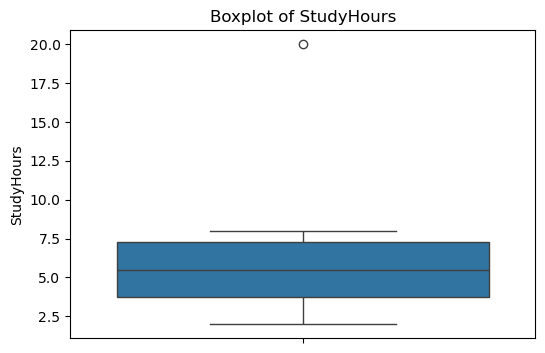

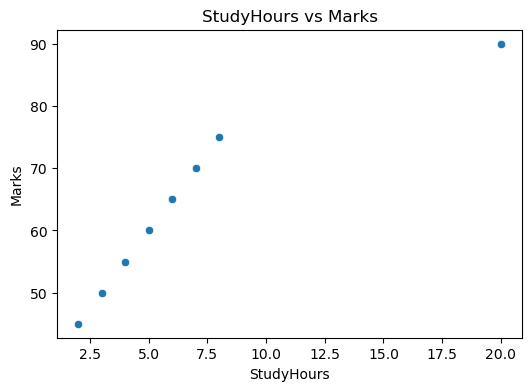

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = { 
    "Student": ["A", "B", "C", "D", "E", "F", "G", "H"],
    "StudyHours": [2, 3, 4, 5, 6, 7, 8, 20],
    "Marks": [45, 50, 55, 60, 65, 70, 75, 90]
}
df = pd.DataFrame(data)

def visualize_data(df, column):

    plt.figure(figsize=(6, 4))
    sns.boxplot(y=df[column])
    plt.title("Boxplot of " + column)
    plt.ylabel(column)
    plt.show()

    plt.figure(figsize=(6, 4))
    sns.scatterplot(x=df[column], y=df["Marks"])
    plt.title(column + " vs Marks")
    plt.xlabel(column)
    plt.ylabel("Marks")
    plt.show()

visualize_data(df, "StudyHours")

3. Implement a linear regression model using scikit-learn's LinearRegression on a housing dataset. Calculate and print the Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), and R² score on the test set. 

In [12]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

df = pd.read_csv("USA_Housing.csv")

X = df[["Avg. Area Income", "Avg. Area House Age", "Avg. Area Number of Rooms", "Avg. Area Number of Bedrooms", "Area Population"]]
y = df["Price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

rmse = mean_squared_error(y_test, y_pred) **0.5
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("RMSE:", rmse)
print("MAE:", mae)
print("R^2 Score:", r2)

RMSE: 100341.52954485502
MAE: 81135.5660933688
R^2 Score: 0.9146818498754005


4. Write a Python program to load the Iris dataset, train a LogisticRegression model, and output the predicted classes for the test dataset. 

In [13]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

iris = load_iris()

X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

model = LogisticRegression(max_iter=200)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Predicted classes:")
print(y_pred)

Predicted classes:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0 0 0 1 0 0 2 1
 0 0 0 2 1 1 0 0]


5. Implement a K-Nearest Neighbors (KNN) classifier with n_neighbors=5. After training and testing the model, write the code to compute and display its confusion matrix using scikit-learn utilities. 

In [14]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix

iris = load_iris()

X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]


6. Write a script to compare a single Decision Tree Classifier against a Random Forest Classifier on a binary classification dataset. Print the accuracy score of both models to determine which performed better. 

In [15]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

data = load_breast_cancer()

X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)
dt_accuracy = accuracy_score(y_test, dt_pred)

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Decision Tree Accuracy:", dt_accuracy)
print("Random Forest Accuracy:", rf_accuracy)

if rf_accuracy > dt_accuracy:
    print("Random Forest performed better.")
else:
    print("Decision Tree performed better.")

Decision Tree Accuracy: 0.9415204678362573
Random Forest Accuracy: 0.9707602339181286
Random Forest performed better.


7. Given a set of true labels and predicted labels, write code to manually calculate or use scikit-learn to extract the precision, recall, and F1-score for a specific target class without using the full classification_report. 

In [16]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_true = [0, 1, 1, 0, 1, 0, 1, 1]
y_pred = [0, 1, 0, 0, 1, 1, 1, 0]

precision = precision_score(y_true, y_pred, pos_label=1)
recall = recall_score(y_true, y_pred, pos_label=1)
f1 = f1_score(y_true, y_pred, pos_label=1)

print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Precision: 0.75
Recall: 0.6
F1-score: 0.6666666666666666


8. Implement a 5-fold cross-validation routine using KFold and cross_val_score to evaluate the stability of a Ridge regression model on a continuous target variable. 

In [17]:
from sklearn.datasets import load_diabetes
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, cross_val_score

data = load_diabetes()

X = data.data
y = data.target

model = Ridge(alpha=1.0)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(model, X, y, cv=kf, scoring="r2")

print("R^2 scores for each fold:")
print(scores)
print("Mean R^2 score:", scores.mean())

R^2 scores for each fold:
[0.41915293 0.45201323 0.33243928 0.50045558 0.34243974]
Mean R^2 score: 0.4093001508128283


9. Write a Python snippet utilizing GridSearchCV to find the optimal hyperparameters for a Random Forest Classifier. Search across n_estimators ([50, 100, 200]) and max_depth ([None, 10, 20]). 

In [21]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier

data = load_breast_cancer()

X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

rf = RandomForestClassifier(random_state=42)

param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 10, 20]
}

grid = GridSearchCV(
    rf,
    param_grid,
    cv=5,
    scoring="accuracy"
)

grid.fit(X_train, y_train)

print("Best parameters:")
print(grid.best_params_)

print("Best accuracy:")
print(grid.best_score_)

Best parameters:
{'max_depth': None, 'n_estimators': 200}
Best accuracy:
0.9522151898734176


10. Create a complete scikit-learn Pipeline that chains a MinMaxScaler preprocessing step with a LogisticRegression classifier, then fit the entire pipeline on training data and evaluate it on test data. 

In [23]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

iris = load_iris()

X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

pipeline = Pipeline([
    ("scaler", MinMaxScaler()),
    ("classifier", LogisticRegression(max_iter=200))
])

pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Test Accuracy:", accuracy)

Test Accuracy: 0.9111111111111111
